In [1]:
from pathlib import Path 
from email import message_from_string
from email.policy import EmailPolicy

import bs4

__POLICY = EmailPolicy()
"""This policy is meant to drive the parsing of email messages and turn them into EmailMessage rather than Message."""

def text_content(path: Path) -> str | None:
    """
    Return the text content of an email.

    Note: this function silently swallows any exception it encounters and returns None when that happens.
    """
    try:
        txt  = path.read_text(encoding="utf8")
        eml  = message_from_string(txt, policy=__POLICY)
        soup = bs4.BeautifulSoup(eml.get_body().get_payload(), "html.parser")
        return soup.get_text(separator="\n")
    except:
        return None

def __convers(text: str, mark: str) -> Conversation | None:
    """Crée une conversation sur base du texte d'un mail qui a été extrait."""
    splits = text.split(mark)
    if splits and len(splits) > 1:
        response = splits[0]
        question = text[len(response):]
        return Conversation(question=question, response=response)
    else:
        return None


def split_convers(text: str | None) -> Conversation | None:
    """Crée une conversation sur base du texte d'un mail qui a été extrait."""
    if not text:
        return None

    if convers := __convers(text, "<digita@arch.be>"):
        return convers

    if convers := __convers(text, "<DIVA@arch.be>"):
        return convers
    
    if convers := __convers(text, "digita"):
        return convers
    
    if convers := __convers(text, "-----Message d'origine-----"):
        return convers
    
    if convers := __convers(text, "-----Oorspronkelijk bericht-----"):
        return convers
    
    return None

def conversation(path: Path) -> Conversation | None:
    """Renvoie la question originale d'un mail."""
    # TODO: Veut-on garder le destinataire du mail ? eml["To"] dans les métadonnées associées.
    return split_convers( text_content(path) )



In [2]:
from tqdm import tqdm 

convers = (conversation(x) for x in Path("../sent/").glob("*.eml")) 
convers = [x for x in tqdm(convers) if x ]

4254it [00:07, 579.02it/s]


In [3]:
from langchain_huggingface.embeddings import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name   = "intfloat/multilingual-e5-large-instruct", 
    model_kwargs = {"device": "cuda"},
)

/home/xgillard/rag/lib64/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
encoded = embeddings.embed_documents([c.response for c in convers])

In [5]:
import numpy as np

encoded = np.array(encoded)
encoded.shape

(2815, 1024)

In [6]:
#from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

tsne   = TSNE(n_components=2)
fitted = tsne.fit_transform(encoded)

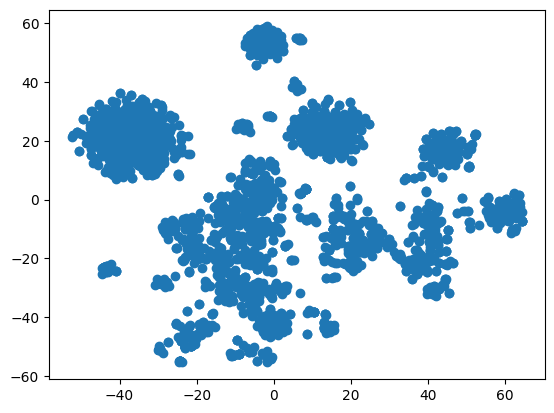

In [8]:
import matplotlib.pyplot as plt

fig = plt.figure()
ax  = fig.add_subplot()

ax.scatter(fitted[:, 0], fitted[:, 1])

In [38]:
from sklearn.cluster import KMeans

kmeans    = KMeans(n_clusters=10)
clustered = kmeans.fit_transform(encoded)
labels    = kmeans.labels_ #clustered.argmax(axis=-1)

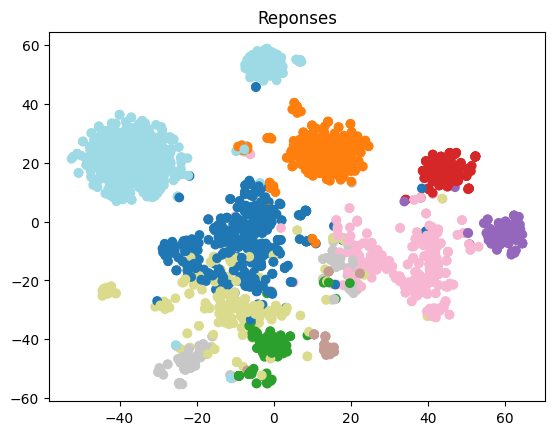

In [42]:
import matplotlib.cm

fig = plt.figure()
ax  = fig.add_subplot()
ax.set_title("Reponses")
ax.scatter(fitted[:, 0], fitted[:, 1], c=labels, cmap=matplotlib.colormaps["tab20"])

In [45]:
encoded = embeddings.embed_documents([c.question for c in convers])
encoded = np.array(encoded)

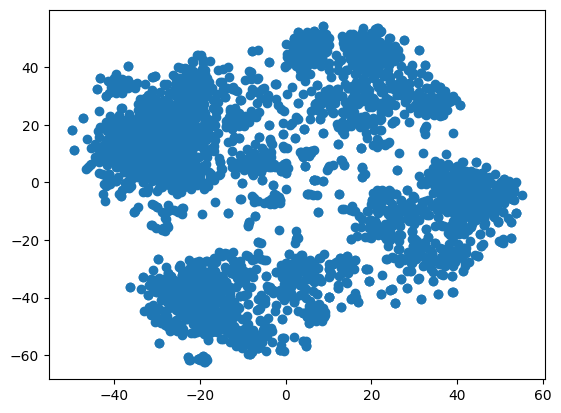

In [46]:
tsne   = TSNE(n_components=2)
fitted = tsne.fit_transform(encoded)


fig    = plt.figure()
ax     = fig.add_subplot()

ax.scatter(fitted[:, 0], fitted[:, 1])

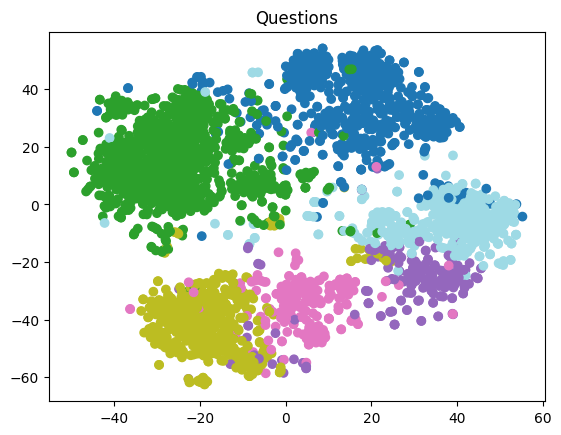

In [55]:
# y a t il une aussi belle découpe en clusters pour les questions que pour les réponses ? 
# => partiellement, oui. 
kmeans = KMeans(n_clusters=6)
kmeans.fit(encoded)
labels = kmeans.labels_

fig = plt.figure()
ax  = fig.add_subplot()
ax.set_title("Questions")
ax.scatter(fitted[:, 0], fitted[:, 1], c=labels, cmap=matplotlib.colormaps["tab20"])